# Módulo 6 — Práctica: ejecución de punta a punta

Paso 3 de la práctica del **Día 10** (ver [`README.md`](../README.md)):
correr el flujo completo (entrada → salida → validación) sobre un caso
**nuevo**, usando solo las funciones de `proyecto_demo/pipeline/` y los
parámetros de `proyecto_demo/config.py` — sin volver a escribir lógica.

**El caso nuevo: Lima, 14 al 17 de marzo de 2025.** Validamos el pronóstico
real de GFS para esos días contra estaciones **reales**: Lima-Callao
(aeropuerto Jorge Chávez, OMM 84628) y 5 estaciones automáticas de
SENAMHI repartidas por la ciudad, desde 56 m hasta 553 m de altura.

In [1]:
import sys, os
BASE = "proyecto_demo"
sys.path.insert(0, BASE)
sys.path.insert(0, f"{BASE}/pipeline")

import importlib
import config as cfg
import descarga, visualizacion, validacion
for m in [cfg, descarga, visualizacion, validacion]:
    importlib.reload(m)

# Caso NUEVO: distinto al usado en 02_practica_montaje_pipeline.ipynb
cfg.CASO.update({
    "nombre": "Lima, marzo 2025",
    "fecha_inicio": "2025-03-14",
    "fecha_fin": "2025-03-17",
    "area": [-9, -80, -15, -74],  # costa central del Perú
    "estacion_validacion": {"nombre": "Lima-Callao", "lat": -12.0167, "lon": -77.1167,
                            "archivo_obs": "Lima_2025_03_horario.csv"},
    "estaciones_senamhi": "estaciones_lima.json",  # en data/senamhi/
    "ciclo_gfs": "2025-03-14 00:00",       # pronóstico de GFS que vamos a validar
    "horas_gfs": list(range(0, 73, 3)),    # de 0 a 72 h, cada 3 h (como la estación)
    "seed": 777,
})

# Persistir el caso actualizado en config.py, para que sea el mismo que
# lea el notebook de cierre (04_entregable_proyecto_final.ipynb) al
# reimportar config.py de forma independiente.
with open(f"{BASE}/config.py") as f:
    contenido_config = f.read()

import re
nuevo_bloque_caso = "CASO = " + repr(cfg.CASO)
contenido_config = re.sub(r"CASO = \{.*?\}\n", nuevo_bloque_caso + "\n", contenido_config, flags=re.DOTALL)

with open(f"{BASE}/config.py", "w") as f:
    f.write(contenido_config)

print("config.py actualizado con el caso nuevo.")
cfg.CASO

config.py actualizado con el caso nuevo.


{'fecha_inicio': '2025-03-14',
 'fecha_fin': '2025-03-17',
 'area': [-9, -80, -15, -74],
 'estacion_validacion': {'nombre': 'Lima-Callao',
  'lat': -12.0167,
  'lon': -77.1167,
  'archivo_obs': 'Lima_2025_03_horario.csv'},
 'seed': 777,
 'nombre': 'Lima, marzo 2025',
 'estaciones_senamhi': 'estaciones_lima.json',
 'ciclo_gfs': '2025-03-14 00:00',
 'horas_gfs': [0,
  3,
  6,
  9,
  12,
  15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72]}

## Etapa 1 — Entrada (Módulo 3)

In [2]:
ok, resultado = descarga.obtener_entrada_wrf(cfg.CASO, cfg.RUTAS)
print("¿Entrada obtenida y verificada?", ok)
print("Ruta:", resultado)

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


¿Entrada obtenida y verificada? True
Ruta: proyecto_demo/datos/entrada/2025-03-14_2025-03-17.nc


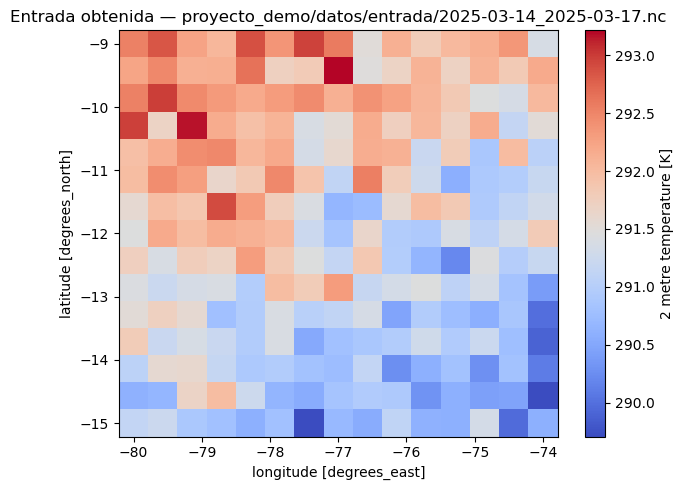

In [3]:
import xarray as xr
import matplotlib.pyplot as plt

if ok:
    fig, ax = plt.subplots(figsize=(6.5, 5))
    xr.open_dataset(resultado)["t2m"].isel(time=0).plot(ax=ax, cmap="coolwarm")
    ax.set_title(f"Entrada obtenida — {resultado}")
    fig.tight_layout()
    plt.show()

## Etapa 2 — Salida (Módulo 4)

En un flujo real, aquí correría el WRF con los datos de la Etapa 1 (fuera
del alcance de este curso). Como no tenemos una corrida del WRF sobre Lima,
generamos una salida **simulada**, centrada en Lima, solo para practicar
el mapa. **No la usamos para validar:** en la Etapa 3 validamos un
pronóstico real.

In [4]:
from synth_data_wrfout import wrfout_sintetico

ds_wrfout_crudo = wrfout_sintetico(
    cen_lat=(cfg.CASO["area"][0] + cfg.CASO["area"][2]) / 2,
    cen_lon=(cfg.CASO["area"][1] + cfg.CASO["area"][3]) / 2,
    start=cfg.CASO["fecha_inicio"] + "T00:00:00", ntime=13,
    seed=cfg.CASO["seed"],
)
ruta_wrfout = f"{cfg.RUTAS['wrfout']}/wrfout_caso_nuevo.nc"
ds_wrfout_crudo.to_netcdf(ruta_wrfout)

ds = visualizacion.abrir_wrfout(ruta_wrfout)
ruta_mapa = visualizacion.guardar_mapa_temperatura(
    ds, f"{cfg.RUTAS['resultados_mapas']}/t2_caso_nuevo.png", paso_tiempo=0,
)
print("Mapa guardado:", ruta_mapa)

Mapa guardado: proyecto_demo/resultados/mapas/t2_caso_nuevo.png


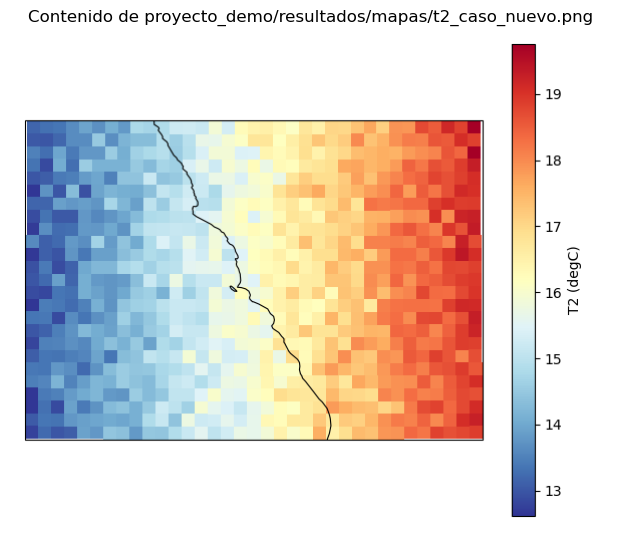

In [5]:
# El mapa ya se guardó a disco arriba (guardar_mapa_temperatura) -- lo
# mostramos también aquí, no solo el archivo, para verlo sin salir del notebook.
from PIL import Image

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(Image.open(ruta_mapa))
ax.axis("off")
ax.set_title(f"Contenido de {ruta_mapa}")
fig.tight_layout()
plt.show()

## Etapa 3 — Validación (Módulo 5), con datos reales

Validamos el **pronóstico de GFS** (el mismo tipo de dato que alimentaría
al WRF, Módulo 3) contra estaciones reales. Cuando tengan su propia
corrida del WRF sobre Lima, solo cambia el pronóstico: se toma de su
`wrfout` con `visualizacion.serie_temperatura_en_punto`. El resto queda igual.

**Paso 1: traer los datos.** Herbie baja solo la temperatura a 2 m (menos
de 1 MB por hora de pronóstico). Si no hay internet, se usa la copia
guardada en `data/modelos/`.

In [6]:
import json
import shutil
import pandas as pd

estacion = cfg.CASO["estacion_validacion"]

# Observaciones: se copian a datos/observaciones (orden del Módulo 3)
# 1) Lima-Callao, mensaje SYNOP de OGIMET (Módulo 5)
ruta_obs = f"{cfg.RUTAS['observaciones']}/{estacion['archivo_obs']}"
shutil.copy(f"../../../data/obs/{estacion['archivo_obs']}", ruta_obs)
obs = validacion.leer_observaciones(ruta_obs)

# 2) Estaciones automáticas de SENAMHI
senamhi = json.load(open(f"../../../data/senamhi/{cfg.CASO['estaciones_senamhi']}", encoding="utf-8"))
obs_senamhi = {}
for est in senamhi:
    ruta = f"{cfg.RUTAS['observaciones']}/{est['archivo']}"
    shutil.copy(f"../../../data/senamhi/{est['archivo']}", ruta)
    obs_senamhi[est["codigo"]] = validacion.leer_senamhi(ruta)

# Pronóstico de GFS en el punto de grilla más cercano a cada estación
puntos = {"Lima-Callao": (estacion["lat"], estacion["lon"])}
puntos.update({est["codigo"]: (est["lat"], est["lon"]) for est in senamhi})
try:
    gfs = descarga.series_gfs_en_puntos(cfg.CASO["ciclo_gfs"], cfg.CASO["horas_gfs"], puntos,
                                        carpeta=f"{cfg.RUTAS['entrada']}/gfs")
    print("GFS descargado con Herbie.")
except Exception as e:
    print(f"Sin descarga ({type(e).__name__}): se usa la copia de data/modelos/.")
    gfs = pd.read_csv("../../../data/modelos/gfs_lima_20250314_00z.csv", comment="#",
                      parse_dates=["tiempo_utc"], index_col="tiempo_utc").drop(columns="fxx")

# Lima-Callao: nos quedamos solo con las horas que están en las dos series
obs, sim = obs.align(gfs["Lima-Callao"].rename("gfs"), join="inner")
print(f"Lima-Callao: {len(obs)} horas en común, de {obs.index[0]} a {obs.index[-1]} (UTC)")
print(f"SENAMHI: {len(senamhi)} estaciones leídas")

GFS descargado con Herbie.
Lima-Callao: 25 horas en común, de 2025-03-14 00:00:00 a 2025-03-17 00:00:00 (UTC)
SENAMHI: 5 estaciones leídas


**Paso 2: mirar los datos antes de calcular nada.** Empezamos por
Lima-Callao. ¿Ven algo raro?

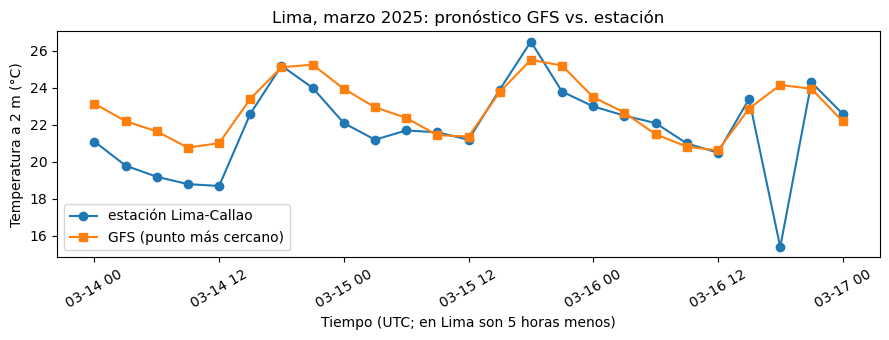

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(obs.index, obs.values, "o-", label="estación Lima-Callao")
ax.plot(sim.index, sim.values, "s-", label="GFS (punto más cercano)")
ax.set_xlabel("Tiempo (UTC; en Lima son 5 horas menos)")
ax.set_ylabel("Temperatura a 2 m (°C)")
ax.set_title(f"{cfg.CASO['nombre']}: pronóstico GFS vs. estación")
ax.legend()
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(f"{cfg.RUTAS['resultados_series']}/serie_lima.png", dpi=100)
plt.show()

El 16 de marzo a las 18 UTC (13 h en Lima) la estación marca **15,4 °C**,
entre dos valores de unos 24 °C. Bajar 8 °C en pleno mediodía y
recuperarse tres horas después no es creíble: lo más probable es un error
al registrar o transmitir el dato. Comparemos las métricas **con** y
**sin** ese dato.

In [8]:
dudoso = obs.index == pd.Timestamp("2025-03-16 18:00")

casos_validacion = {
    "Lima (todos los datos)": (obs, sim),
    "Lima (sin el dato dudoso)": (obs[~dudoso], sim[~dudoso]),
}
tabla = validacion.evaluar_variable(casos_validacion, nombre_variable="T2")
tabla.round(3).to_csv(f"{cfg.RUTAS['resultados_validacion']}/validacion_caso_nuevo.csv")
tabla.round(2)

,variable,MAE,RMSE,bias,r,KGE
estacion,,,,,,
Lima (todos los datos),T2,1.28,2.15,1.01,0.57,0.44
Lima (sin el dato dudoso),T2,0.97,1.27,0.69,0.84,0.72


**Qué nos dice la tabla:**

- **Un solo dato malo, de 25, cambia la historia:** la correlación baja de
  0,84 a 0,57 y el RMSE casi se duplica. Por eso los datos se miran antes
  de validar.
- **Sin ese dato, GFS reproduce bien el ciclo del día en Lima-Callao**
  (r ≈ 0,84), pero es algo más cálido que la estación (sesgo ≈ +0,7 °C).

**Paso 3: una celda, varios lugares.** Lima-Callao es una sola estación.
SENAMHI tiene estaciones automáticas, con datos cada hora, repartidas por
la ciudad. Usamos 5, de la costa hacia los cerros.

Sus archivos no vienen como los de OGIMET: la fecha está en 4 columnas
(`Año`, `Mes`, `Día`, `Hora`), la hora es **local** (UTC−5) y los datos
faltantes dicen `S/D`. `validacion.leer_senamhi` resuelve las tres cosas:
si no se pasa la hora a UTC, se compararía el mediodía de Lima con las 7 de
la mañana.

In [9]:
casos_senamhi = {}
for est in senamhi:
    o, s = obs_senamhi[est["codigo"]].align(gfs[est["codigo"]], join="inner")
    casos_senamhi[f"{est['nombre']} ({est['alt_m']} m)"] = (o, s)

tabla_senamhi = validacion.evaluar_variable(casos_senamhi, nombre_variable="T2")
tabla_senamhi.round(3).to_csv(f"{cfg.RUTAS['resultados_validacion']}/validacion_senamhi.csv")

# ¿Cuántas estaciones caen en la misma celda de GFS?
print("Estaciones con el mismo valor de GFS que Campo de Marte:",
      [c for c in gfs.columns if gfs[c].equals(gfs["112181"])])
tabla_senamhi.round(2)

Estaciones con el mismo valor de GFS que Campo de Marte: ['Lima-Callao', '112265', '112181', '472AC278', '112278']


,variable,MAE,RMSE,bias,r,KGE
estacion,,,,,,
San Martin De Porres (56 m),T2,0.91,1.07,-0.25,0.85,0.72
Campo De Marte (117 m),T2,1.04,1.29,0.27,0.80,0.65
Von Humboldt (247 m),T2,1.36,1.96,-0.71,0.82,0.47
Ceres (339 m),T2,1.75,2.24,-1.75,0.81,0.59
Ñaña (553 m),T2,3.44,3.48,-3.44,0.97,0.84


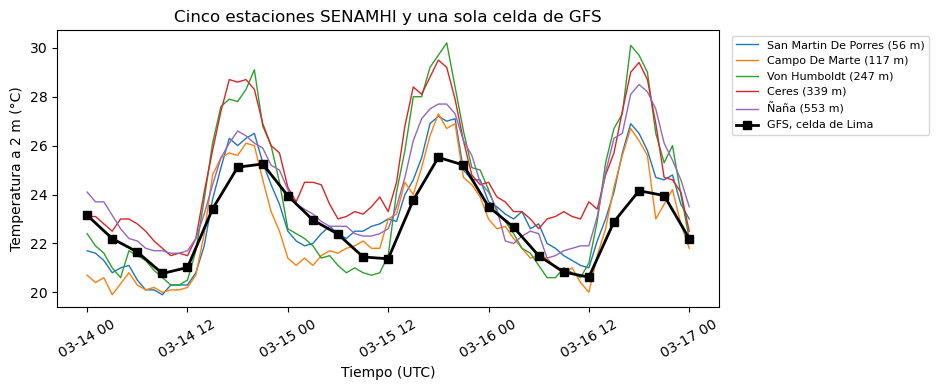

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4))
for est in senamhi:
    o = obs_senamhi[est["codigo"]].loc[gfs.index[0]:gfs.index[-1]]
    ax.plot(o.index, o.values, lw=1, label=f"{est['nombre']} ({est['alt_m']} m)")
ax.plot(gfs.index, gfs["112181"], "ks-", lw=2, label="GFS, celda de Lima")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("Temperatura a 2 m (°C)")
ax.set_title("Cinco estaciones SENAMHI y una sola celda de GFS")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(f"{cfg.RUTAS['resultados_series']}/serie_senamhi.png", dpi=100)
plt.show()

**Qué nos dice:**

- **Cuatro de las cinco estaciones (y también Lima-Callao) caen en la misma
  celda de GFS:** el modelo les da exactamente el mismo número. Pero las
  estaciones no marcan lo mismo: cerca de la costa (San Martín de Porres)
  GFS casi no tiene sesgo; en Ceres, a 339 m y lejos del mar, GFS queda
  casi 2 °C por debajo.
- **Ñaña cae en la celda vecina**, que ya sube hacia los Andes: GFS sigue
  muy bien su ciclo del día (r ≈ 0,97), pero la enfría unos 3,4 °C.
- **Con celdas de 25 km, GFS no distingue la costa del valle.** Un WRF con
  celdas de 1 a 3 km sí podría: esa es la pregunta que pueden responder
  con su propia corrida.

## Resumen de la ejecución de punta a punta

In [11]:
print("=== Resumen del caso ===")
print(f"Caso:               {cfg.CASO['nombre']}")
print(f"Periodo:            {cfg.CASO['fecha_inicio']} a {cfg.CASO['fecha_fin']}")
print(f"Pronóstico validado: GFS, ciclo {cfg.CASO['ciclo_gfs']} UTC")
print(f"Área:                {cfg.CASO['area']}")
print(f"Estaciones:          {estacion['nombre']} (SYNOP) + {len(senamhi)} de SENAMHI")
print()
print("Archivos generados:")
for ruta in [
    resultado,
    ruta_wrfout,
    ruta_mapa,
    ruta_obs,
    f"{cfg.RUTAS['resultados_series']}/serie_lima.png",
    f"{cfg.RUTAS['resultados_series']}/serie_senamhi.png",
    f"{cfg.RUTAS['resultados_validacion']}/validacion_senamhi.csv",
    f"{cfg.RUTAS['resultados_validacion']}/validacion_caso_nuevo.csv",
]:
    existe = os.path.exists(ruta)
    print(f"  [{'OK' if existe else 'FALTA'}] {ruta}")

=== Resumen del caso ===
Caso:               Lima, marzo 2025
Periodo:            2025-03-14 a 2025-03-17
Pronóstico validado: GFS, ciclo 2025-03-14 00:00 UTC
Área:                [-9, -80, -15, -74]
Estaciones:          Lima-Callao (SYNOP) + 5 de SENAMHI

Archivos generados:
  [OK] proyecto_demo/datos/entrada/2025-03-14_2025-03-17.nc
  [OK] proyecto_demo/datos/wrfout/wrfout_caso_nuevo.nc
  [OK] proyecto_demo/resultados/mapas/t2_caso_nuevo.png
  [OK] proyecto_demo/datos/observaciones/Lima_2025_03_horario.csv
  [OK] proyecto_demo/resultados/series/serie_lima.png
  [OK] proyecto_demo/resultados/series/serie_senamhi.png
  [OK] proyecto_demo/resultados/validacion/validacion_senamhi.csv
  [OK] proyecto_demo/resultados/validacion/validacion_caso_nuevo.csv


## Cierre

Entregable parcial: `proyecto_demo/` con los tres productos (entrada
verificada, mapa, validación) del caso nuevo. Continuar con
[`04_entregable_proyecto_final.ipynb`](04_entregable_proyecto_final.ipynb).